In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append("../")

import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
import urllib.request
import zipfile

In [ ]:
URL = "https://api.insee.fr/melodi/file/DS_RP_EMPLOI_LR_COMP/DS_RP_EMPLOI_LR_COMP_2023_CSV_FR"
urllib.request.urlretrieve(URL, "emploi.zip")

with zipfile.ZipFile("emploi.zip") as z:
    with z.open("DS_RP_EMPLOI_LR_COMP_2023_data.csv") as f:
        emploi = pd.read_csv(f, sep=";", dtype={"GEO": str, "EMPSTA_ENQ": str})

In [ ]:

emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO_OBJECT','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["GEO_OBJECT"] == "DEP"]
emploi_dep = emploi_dep.loc[emploi_dep["TIME_PERIOD"] == 2023]
emploi_dep = emploi_dep.loc[emploi_dep["EMPSTA_ENQ"] == "1T2"]

emploi_dep = emploi_dep.pivot(index=["GEO"], columns="PCS", values="OBS_VALUE")
emploi_dep = emploi_dep.reset_index()

emploi_dep.head()

PCS,GEO,1,2,3,4,5,6,_T
0,01,2863.11774,22439.73589,56516.54738,89808.06197,84144.48420,76290.25921,332062.20638
1,02,3686.00975,12116.77122,21318.12169,52885.87481,68088.63646,68943.12956,227038.54348
2,03,4047.28690,9587.33737,14185.24139,32322.46130,42133.41982,35974.06815,138249.81493
3,04,1918.00573,7329.93542,9317.30725,18339.33787,20144.32539,14170.78771,71219.69936
4,05,1688.23274,6422.68214,7304.44103,18020.50056,19215.67253,11504.59081,64156.11979


In [30]:
emploi_dep["Part d'agriculteurs dans la population active"]=emploi_dep["1"]/emploi_dep["_T"]

emploi_dep["Part d'artisans, commerçants et chefs d'entreprises dans la population active"]=emploi_dep["2"]/emploi_dep["_T"]
emploi_dep["Part de cadres dans la population active"]=emploi_dep["3"]/emploi_dep["_T"]
emploi_dep["Part de professions intermédiaires dans la population active"]=emploi_dep["4"]/emploi_dep["_T"]
emploi_dep["Part d'employés dans la population active"]=emploi_dep["5"]/emploi_dep["_T"]
emploi_dep["Part d'ouvriers dans la population active"]=emploi_dep["6"]/emploi_dep["_T"]

emploi_dep = emploi_dep.drop(columns=["1", "2", "3", "4", "5", "6"])
emploi_dep.head()

PCS,GEO,_T,Part d'agriculteurs dans la population active,"Part d'artisans, commerçants et chefs d'entreprises dans la population active",Part de cadres dans la population active,Part de professions intermédiaires dans la population active,Part d'employés dans la population active,Part d'ouvriers dans la population active
0,01,332062.20638,0.008622,0.067577,0.170199,0.270456,0.253400,0.229747
1,02,227038.54348,0.016235,0.053369,0.093896,0.232938,0.299899,0.303663
2,03,138249.81493,0.029275,0.069348,0.102606,0.233798,0.304763,0.260211
3,04,71219.69936,0.026931,0.102920,0.130825,0.257504,0.282848,0.198973
4,05,64156.11979,0.026314,0.100110,0.113854,0.280885,0.299514,0.179322


In [1]:
URL = "https://data.education.gouv.fr/api/explore/v2.1/catalog/datasets/fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique/exports/csv?use_labels=true"
bac = pd.read_csv(URL,sep=";",low_memory=False)

NameError: name 'pd' is not defined

In [ ]:


bac["Nombre de réussites"] = bac["Presents - Toutes series"]*bac["Taux de reussite - Toutes series"]/100
bac["Nombre de mentions"] = bac["Presents - Toutes series"]*bac["Taux de mentions - Toutes series"]/100
bac["Nombre acces 2nde-bac pondéré"] = bac["Taux d'acces 2nde-bac"]*bac["Presents - Toutes series"]/100

bac = bac.groupby(["Code departement","Annee"]).agg({"Presents - Toutes series":"sum",
                                               "Effectif de seconde":"sum",
                                               "Effectif de premiere":"sum",
                                               "Effectif de terminale":"sum",
                                               "Nombre de réussites":"sum",
                                               "Nombre de mentions":"sum",
                                               "Nombre acces 2nde-bac pondéré":"sum"})

bac["Taux de réussite"] = bac["Nombre de réussites"]/bac["Presents - Toutes series"]
bac["Taux de mentions"] = bac["Nombre de mentions"]/bac["Presents - Toutes series"]
bac["Taux de passage 2nde - bac"] = bac["Nombre acces 2nde-bac pondéré"]/bac["Presents - Toutes series"]

bac = bac.drop(columns = ["Nombre de réussites","Nombre de mentions","Nombre acces 2nde-bac pondéré"])

bac= bac.reset_index()
bac= bac[bac["Annee"]==2023]
bac.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
11,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747
23,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077
35,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203
47,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512
59,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974


In [37]:
emploi_dep_bac = emploi_dep.merge(
    bac,
    left_on = ["GEO"],
  right_on = ["Code departement"],
  how = "left"
)

emploi_dep_bac.head()

,GEO,_T,Part d'agriculteurs dans la population active,"Part d'artisans, commerçants et chefs d'entreprises dans la population active",Part de cadres dans la population active,Part de professions intermédiaires dans la population active,Part d'employés dans la population active,Part d'ouvriers dans la population active,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
0,01,332062.20638,0.008622,0.067577,0.170199,0.270456,0.253400,0.229747,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747
1,02,227038.54348,0.016235,0.053369,0.093896,0.232938,0.299899,0.303663,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077
2,03,138249.81493,0.029275,0.069348,0.102606,0.233798,0.304763,0.260211,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203
3,04,71219.69936,0.026931,0.102920,0.130825,0.257504,0.282848,0.198973,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512
4,05,64156.11979,0.026314,0.100110,0.113854,0.280885,0.299514,0.179322,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974


In [39]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part d'agriculteurs dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())
#L'IA m'a aidée dans la production de régressions


                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.089
Model:                               OLS   Adj. R-squared:                  0.080
Method:                    Least Squares   F-statistic:                     9.592
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):            0.00255
Time:                           18:22:10   Log-Likelihood:                 264.66
No. Observations:                    100   AIC:                            -525.3
Df Residuals:                         98   BIC:                            -520.1
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

In [47]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Part d'agriculteurs dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.009
Model:                               OLS   Adj. R-squared:                 -0.001
Method:                    Least Squares   F-statistic:                    0.8848
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):              0.349
Time:                           18:37:39   Log-Likelihood:                 151.94
No. Observations:                    100   AIC:                            -299.9
Df Residuals:                         98   BIC:                            -294.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.103
Model:                               OLS   Adj. R-squared:                  0.094
Method:                    Least Squares   F-statistic:                     11.30
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):            0.00110
Time:                           18:38:03   Log-Likelihood:                 265.45
No. Observations:                    100   AIC:                            -526.9
Df Residuals:                         98   BIC:                            -521.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                                                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

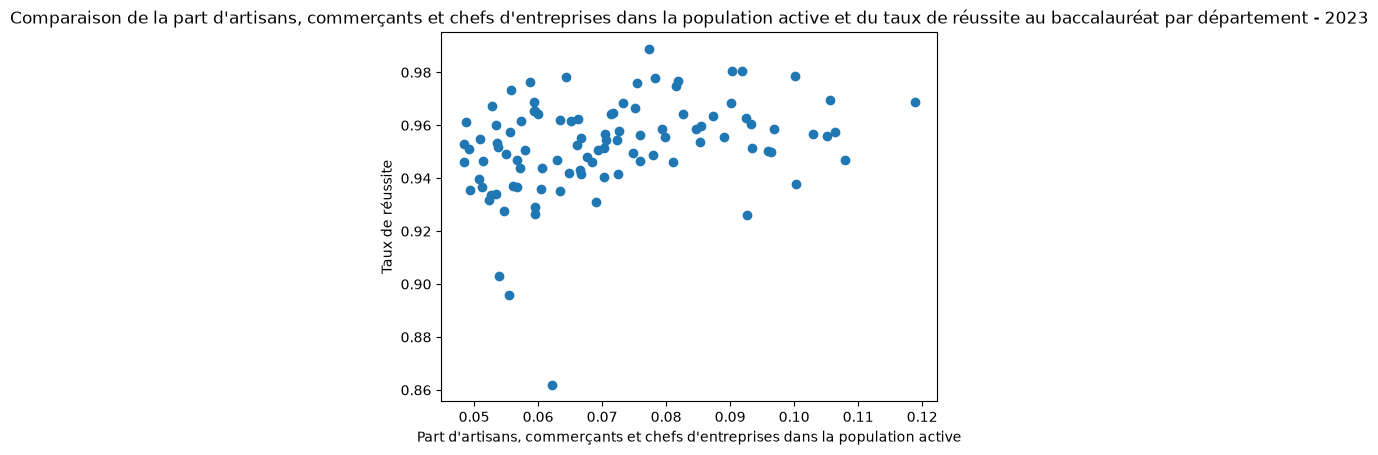

In [ ]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part d'artisans, commerçants et chefs d'entreprises dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

plt.scatter(emploi_dep_bac["Part d'artisans, commerçants et chefs d'entreprises dans la population active"],emploi_dep_bac["Taux de réussite"])
plt.xlabel("Part d'artisans, commerçants et chefs d'entreprises dans la population active")
plt.ylabel("Taux de réussite")
plt.title("Comparaison de la part d'artisans, commerçants et chefs d'entreprises dans la population active et du taux de réussite au baccalauréat par département - 2023")


In [49]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Part d'artisans, commerçants et chefs d'entreprises dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.029
Model:                               OLS   Adj. R-squared:                  0.019
Method:                    Least Squares   F-statistic:                     2.942
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):             0.0895
Time:                           18:38:24   Log-Likelihood:                 152.97
No. Observations:                    100   AIC:                            -301.9
Df Residuals:                         98   BIC:                            -296.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                                                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------

In [41]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part de cadres dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.002
Model:                               OLS   Adj. R-squared:                 -0.008
Method:                    Least Squares   F-statistic:                    0.1676
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):              0.683
Time:                           18:23:21   Log-Likelihood:                 260.08
No. Observations:                    100   AIC:                            -516.2
Df Residuals:                         98   BIC:                            -510.9
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

In [50]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part de cadres dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.002
Model:                               OLS   Adj. R-squared:                 -0.008
Method:                    Least Squares   F-statistic:                    0.1676
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):              0.683
Time:                           18:38:41   Log-Likelihood:                 260.08
No. Observations:                    100   AIC:                            -516.2
Df Residuals:                         98   BIC:                            -510.9
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

In [43]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part de professions intermédiaires dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.009
Model:                               OLS   Adj. R-squared:                 -0.001
Method:                    Least Squares   F-statistic:                    0.9247
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):              0.339
Time:                           18:25:26   Log-Likelihood:                 260.46
No. Observations:                    100   AIC:                            -516.9
Df Residuals:                         98   BIC:                            -511.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

In [44]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part d'employés dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.034
Model:                               OLS   Adj. R-squared:                  0.024
Method:                    Least Squares   F-statistic:                     3.466
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):             0.0656
Time:                           18:25:59   Log-Likelihood:                 261.73
No. Observations:                    100   AIC:                            -519.5
Df Residuals:                         98   BIC:                            -514.3
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [51]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Part d'employés dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.221
Model:                               OLS   Adj. R-squared:                  0.213
Method:                    Least Squares   F-statistic:                     27.72
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           8.28e-07
Time:                           18:39:12   Log-Likelihood:                 163.95
No. Observations:                    100   AIC:                            -323.9
Df Residuals:                         98   BIC:                            -318.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [45]:
results = smf.ols(
    """Q("Taux de réussite") ~ Q("Part d'ouvriers dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de réussite")   R-squared:                       0.006
Model:                               OLS   Adj. R-squared:                 -0.004
Method:                    Least Squares   F-statistic:                    0.6267
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):              0.430
Time:                           18:26:38   Log-Likelihood:                 260.31
No. Observations:                    100   AIC:                            -516.6
Df Residuals:                         98   BIC:                            -511.4
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

In [52]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Part d'ouvriers dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.099
Model:                               OLS   Adj. R-squared:                  0.090
Method:                    Least Squares   F-statistic:                     10.76
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):            0.00144
Time:                           18:39:34   Log-Likelihood:                 156.70
No. Observations:                    100   AIC:                            -309.4
Df Residuals:                         98   BIC:                            -304.2
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

                              OLS Regression Results                             
Dep. Variable:     Q("Taux de mentions")   R-squared:                       0.261
Model:                               OLS   Adj. R-squared:                  0.245
Method:                    Least Squares   F-statistic:                     17.10
Date:                   Sat, 21 Nov 2026   Prob (F-statistic):           4.34e-07
Time:                           18:42:44   Log-Likelihood:                 166.59
No. Observations:                    100   AIC:                            -327.2
Df Residuals:                         97   BIC:                            -319.4
Df Model:                              2                                         
Covariance Type:               nonrobust                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------

Text(0.5, 1.0, "Comparaison de la part d'employés dans la population active et du taux de mentions au baccalauréat par département - 2023")

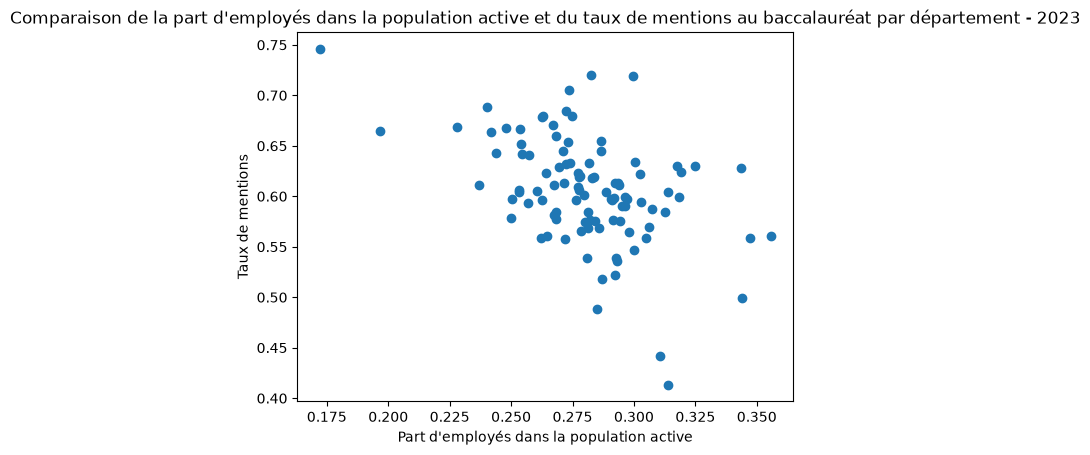

In [54]:
results = smf.ols(
    """Q("Taux de mentions") ~ Q("Part d'ouvriers dans la population active")+Q("Part d'employés dans la population active")""",
    data=emploi_dep_bac
).fit()
print(results.summary())


plt.scatter(emploi_dep_bac["Part d'employés dans la population active"],emploi_dep_bac["Taux de mentions"])
plt.xlabel("Part d'employés dans la population active")
plt.ylabel("Taux de mentions")
plt.title("Comparaison de la part d'employés dans la population active et du taux de mentions au baccalauréat par département - 2023")
